# NMR challenge, Phase 1: shallower circuits with the same (or better) accuracy

**Baseline:** `nmr.ipynb`, which is left unchanged. It uses first-order Lie–Trotter, 2.5 ms steps,
300 time points, all X-basis starting states and an ideal statevector simulation.

**Goal:** the lowest circuit depth that keeps the accuracy of the original spectra, ideally improving
agreement with exact time evolution. Ideal simulation only: no noise, no hardware.

**How candidates are judged:** against exact evolution $e^{-iHt}$ of the same rotating-frame
Hamiltonian, with the same time grid, weights, observables and spectrum code. The acceptance rule
was written before any benchmark ran (`results/phase1/acceptance_criteria.json`). A candidate is
accepted for a molecule only if none of its errors is larger than the baseline's:
- correlation function;
- spectrum RMSE and cosine;
- peak positions and peak heights;
- and every characteristic peak and the matching must survive.

Code: `src/circuit_opt.py` (formulas as NumPy models and as Qiskit circuits, cross-checked) and
`src/phase1_benchmark.py` (metrics). Tests: `tests/test_circuit_opt.py`.
Report: `docs/phase1_circuit_optimization.md`.

In [1]:
import sys, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

sys.path.insert(0, str(Path("src").resolve()))
import circuit_opt as C
import phase1_benchmark as B
import nmr_pipeline as P

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
MOLS = B.MOLS
print("acceptance rule:", json.loads(Path("results/phase1/acceptance_criteria.json").read_text())["accept_rule"])

acceptance rule: A candidate is ACCEPTED for a molecule if E1 <= baseline E1, E2 RMSE <= baseline and cosine >= baseline, E3 <= baseline, E4 <= baseline (each computed for that molecule) and E5 holds. A small numerical slack of 1e-9 absolute is allowed for candidates that are exact rewrites of the baseline.


## 1. What was investigated (details and references in the report)

| Method | Fits this problem? | Measured or derived result |
|---|---|---|
| Better transpilation (level 2/3, block consolidation) | yes, exact rewrite | CNOTs halved, same unitary |
| Commuting groups XX+YY+ZZ per pair → one 3-CNOT block (Heisenberg exchange) | yes, exact rewrite | 9 instead of 18 CNOTs per step |
| Qiskit's Rustiq Pauli-network synthesis | no | 16 CNOTs per step |
| Ordering, Strang splitting, alternating pairs | partly | no gain in line positions (similarity-transform argument); fewer CNOTs with alternation, but slightly worse accuracy |
| 2nd/4th-order Suzuki | no, at this step size | more CNOTs; line shifts unchanged (2nd) or ~9× the cost (4th) |
| Shift (Zeeman) terms folded into the pair blocks | yes | same 9 CNOTs/step, ~3× more accurate |
| Symmetry ΠZ_i (exact) | yes | half the starting states; molecule C needs 1 instead of 4 |
| Fewer Trotter steps | no for A and B | aliasing (fixed signal length) or larger errors (fixed sampling) |
| Randomized formulas (qDRIFT, random ordering) | no | qDRIFT needs ~2(λt)²/ε ≈ 10⁶ gates (λ = Σ\|coefficients\| ≈ 1,000 rad/s) |
| Qubitization / signal processing | no | needs ancillas and multi-controlled block encodings, far deeper for 2–3 qubits |
| **Exact compilation of each time point** e^{-iHt_k} | **yes for 2–3 spins** | 19 CNOTs (3 qubits), 3 CNOTs (2 qubits), at any time, no Trotter error |


## 2. Exact simplifications, checked

In [2]:
for m in MOLS:
    model = C.spin_model(m)
    n = model["n"]
    q = C.pauli_matrix({i: "Z" for i in range(n)}, n)
    units = C.time_point_unitaries("lie", model)
    full, half = C.signals(units, model), C.signals(units, model, half=True)
    print(f"{m}: ||ΠZ H ΠZ - H|| = {np.abs(q @ model['H'] @ q - model['H']).max():.0e}; "
          f"{len(C.x_states(n, True)[0])} of {2**n} starting states give the same signals "
          f"(difference {max(np.abs(a - b).max() for a, b in zip(full, half)):.0e}); "
          f"grouped blocks = baseline circuit: {C.check_model_vs_circuit({'formula': 'lie', 'style': 'grouped'}, model):.0e}")

molecule A: ||ΠZ H ΠZ - H|| = 0e+00; 4 of 8 starting states give the same signals (difference 2e-15); grouped blocks = baseline circuit: 1e-14
molecule B: ||ΠZ H ΠZ - H|| = 0e+00; 4 of 8 starting states give the same signals (difference 4e-15); grouped blocks = baseline circuit: 1e-14
molecule C: ||ΠZ H ΠZ - H|| = 0e+00; 1 of 4 starting states give the same signals (difference 0e+00); grouped blocks = baseline circuit: 2e-15


## 3. Benchmark of all candidates

Every candidate is run on every molecule, every required starting state and both measurement bases
(X and Y), for the deepest time point. The exact candidate is measured over all 299 time points.
Results are shown for all-to-all connectivity and for a 3-qubit line (best of the 6 layouts, SWAPs
counted). Accuracy is measured against exact evolution.

In [3]:
rows, study, alias = B.run()
d = pd.DataFrame(rows)
d["mol"] = d["molecule"].str[-1]
show = d[["candidate", "mol", "deep_depth", "deep_twoq_depth", "deep_cx", "deep_oneq", "line_cx_incl_swaps", "line_swap",
          "circuits_on_hardware", "E1_corr_err", "E2_cosine", "E3_peak_pos_hz", "E4_peak_height_pct",
          "line_shift_hz", "line_height_pct", "E5_science", "accepted", "high_accuracy"]]
display(show.round(4))

C0 baseline (official): done (7 s)


C1 baseline + transpiler level 3: done (11 s)


C2 grouped exchange blocks: done (14 s)


C3 Strang (shift/coupling split): done (18 s)


C3b Strang + alternating pairs: done (21 s)


C4 second-order Suzuki: done (26 s)


... (2 outputs left out)

step study lie: done (38 s)


step study pairfield: done (43 s)


total 43 s


,candidate,mol,deep_depth,deep_twoq_depth,deep_cx,deep_oneq,line_cx_incl_swaps,line_swap,circuits_on_hardware,E1_corr_err,E2_cosine,E3_peak_pos_hz,E4_peak_height_pct,line_shift_hz,line_height_pct,E5_science,accepted,high_accuracy
0,C0 baseline (official),A,13460,5382,5382,13470,6726,448,4784,0.7289,0.9328,1.1228,38.1386,0.7148,19.1470,True,True,False
1,C0 baseline (official),B,13460,5382,5382,13470,6726,448,4784,0.6812,0.9747,0.9171,27.7759,0.4180,15.7423,True,True,False
2,C0 baseline (official),C,4490,1794,1794,4495,1794,0,2392,0.0489,0.9999,0.0450,3.5918,0.0116,0.7254,True,True,False
3,C1 baseline + transpiler level 3,A,7782,2691,2691,9879,4035,448,2392,0.7289,0.9328,1.1228,38.1386,0.7148,19.1470,True,True,False
4,C1 baseline + transpiler level 3,B,8080,2691,2691,10176,4035,448,2392,0.6812,0.9747,0.9171,27.7759,0.4180,15.7423,True,True,False
5,C1 baseline + transpiler level 3,C,16,3,3,23,3,0,598,0.0489,0.9999,0.0450,3.5918,0.0116,0.7254,True,True,False
6,C2 grouped exchange blocks,A,7480,2691,2691,8684,4035,448,2392,0.7289,0.9328,1.1228,38.1386,0.7148,19.1470,True,True,False
7,C2 grouped exchange blocks,B,7778,2691,2691,9280,4035,448,2392,0.6812,0.9747,0.9171,27.7759,0.4180,15.7423,True,True,False
8,C2 grouped exchange blocks,C,16,3,3,23,3,0,598,0.0489,0.9999,0.0450,3.5918,0.0116,0.7254,True,True,False
9,C3 Strang (shift/coupling split),A,7480,2691,2691,8685,4035,448,2392,0.7285,0.9319,1.1234,39.4003,0.7148,39.3513,True,False,False


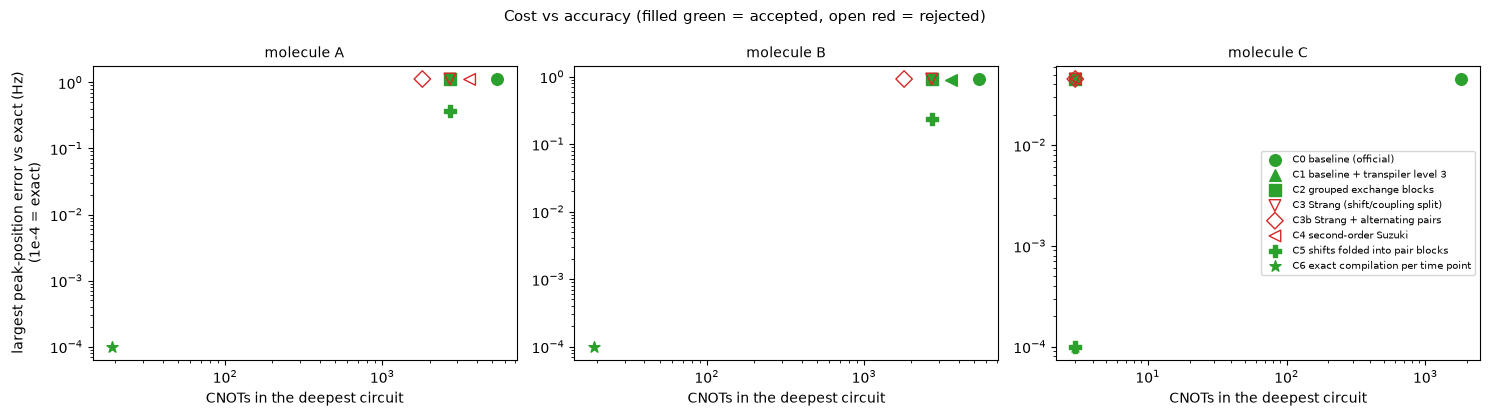

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), dpi=100)
markers = dict(zip(B.CANDIDATES, "o^svD<P*"))
for ax, m in zip(axes, MOLS):
    for name in B.CANDIDATES:
        r = d[(d["candidate"] == name) & (d["molecule"] == m)].iloc[0]
        ax.scatter(r["deep_cx"], max(r["E3_peak_pos_hz"], 1e-4), marker=markers[name], s=70,
                   facecolors="C2" if r["accepted"] else "none", edgecolors="C2" if r["accepted"] else "C3",
                   label=name)
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlabel("CNOTs in the deepest circuit")
    ax.set_title(m, fontsize=10)
axes[0].set_ylabel("largest peak-position error vs exact (Hz)\n(1e-4 = exact)")
axes[2].legend(fontsize=7, loc="center right")
fig.suptitle("Cost vs accuracy (filled green = accepted, open red = rejected)", fontsize=11)
fig.tight_layout()
plt.show()

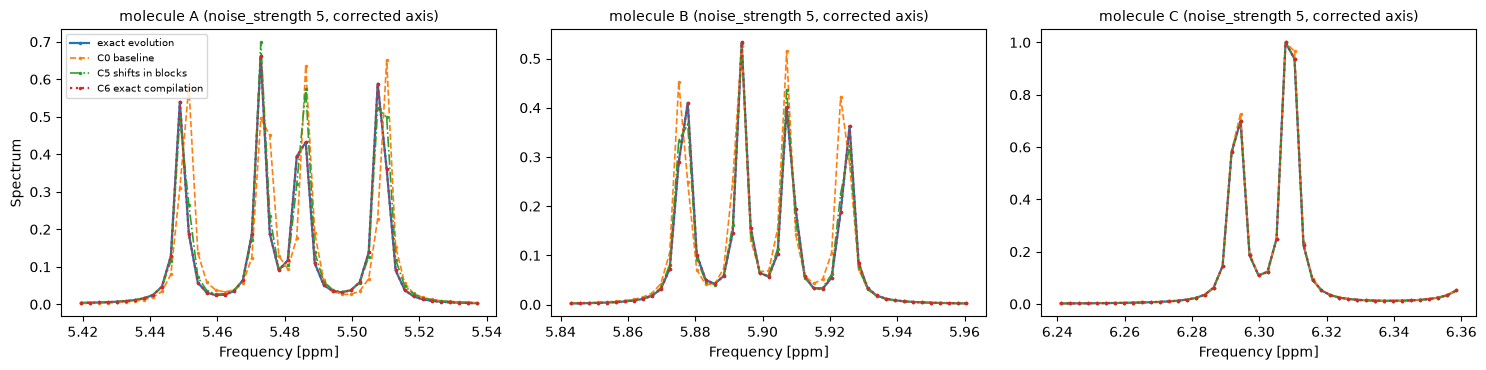

In [5]:
# Spectra: exact vs baseline vs the two best candidates (molecule A, critical multiplet at 5.48 ppm).
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), dpi=100)
zoom = {"molecule A": 5.479, "molecule B": 5.901, "molecule C": 6.30}
for ax, m in zip(axes, MOLS):
    model = C.spin_model(m)
    for label, f, style in (("exact evolution", "exact", "-"), ("C0 baseline", "lie", "--"),
                            ("C5 shifts in blocks", "pairfield", "-."), ("C6 exact compilation", "exact", ":")):
        cx, cy = C.signals(C.time_point_unitaries(f, model), model, half=True)
        s, p, p_true = B.spectrum(cx, cy, model["chem"])
        keep = np.abs(p_true - zoom[m]) < 0.06
        ax.plot(p_true[keep], s[keep], style, marker=".", ms=3, label=label, lw=1.6 if f == "exact" else 1.2)
    ax.set_title(f"{m} (noise_strength 5, corrected axis)", fontsize=10)
    ax.set_xlabel("Frequency [ppm]")
axes[0].set_ylabel("Spectrum")
axes[0].legend(fontsize=7)
fig.tight_layout()
plt.show()

## 4. Can the number of Trotter steps be reduced?

1. **Fixed signal length 0.75 s, larger sampling interval.** The complex signal aliases once the
   sampling interval exceeds 1/(2 × the largest line offset).
2. **Fixed sampling 2.5 ms, fewer and larger Trotter steps.** Time point $t_k$ uses
   $n_k = \lceil t_k/\Delta\rceil$ steps of $t_k/n_k$, so the deepest circuit has 300, 200, 150, 100,
   75 or 50 steps.

,max_line_offset_hz,max_sampling_interval_ms,min_time_points_for_0.75s
molecule A,148.71,3.36,224.0
molecule B,159.20,3.14,239.0
molecule C,22.63,22.09,34.0


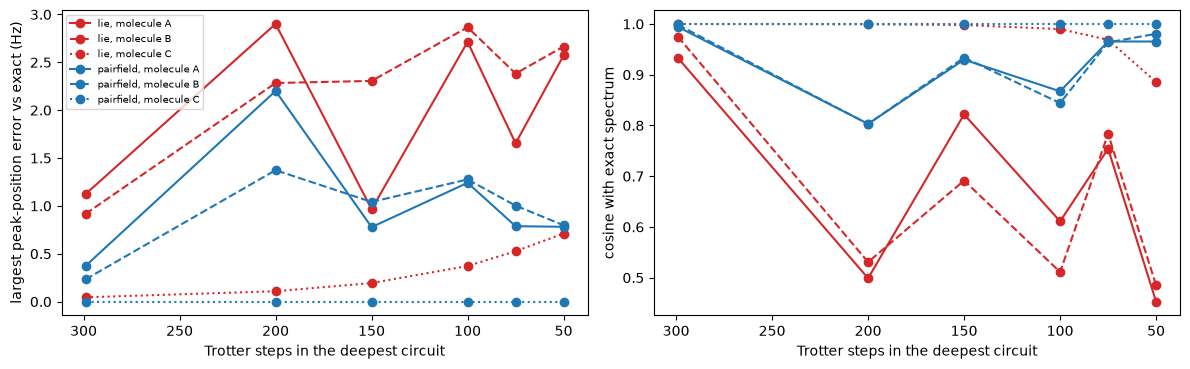

,formula,trotter_step_ms,deepest_steps,mol,deep_cx,E3_peak_pos_hz,E4_peak_height_pct,E2_cosine,E5_science,accepted
0,lie,2.50,299,A,2691,1.123,38.139,0.933,True,True
1,lie,2.50,299,B,2691,0.917,27.776,0.975,True,True
2,lie,2.50,299,C,3,0.045,3.592,1.000,True,True
3,lie,3.75,200,A,1800,2.901,90.570,0.499,False,False
4,lie,3.75,200,B,1800,2.284,84.788,0.531,False,False
5,lie,3.75,200,C,3,0.108,7.964,0.999,True,False
6,lie,5.00,150,A,1350,0.965,61.591,0.822,True,False
7,lie,5.00,150,B,1350,2.306,55.874,0.691,True,False
8,lie,5.00,150,C,3,0.194,9.094,0.998,True,False
9,lie,7.50,100,A,900,2.714,82.438,0.611,True,False


In [6]:
display(pd.DataFrame(alias).T.round(2))
s = pd.DataFrame(study)
s["mol"] = s["molecule"].str[-1]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), dpi=100)
for f, color in (("lie", "C3"), ("pairfield", "C0")):
    for m, ls in zip(MOLS, ("-", "--", ":")):
        r = s[(s["formula"] == f) & (s["molecule"] == m)]
        axes[0].plot(r["deepest_steps"], r["E3_peak_pos_hz"], ls, marker="o", color=color, label=f"{f}, {m}")
        axes[1].plot(r["deepest_steps"], r["E2_cosine"], ls, marker="o", color=color)
axes[0].set_ylabel("largest peak-position error vs exact (Hz)")
axes[1].set_ylabel("cosine with exact spectrum")
for ax in axes:
    ax.set_xlabel("Trotter steps in the deepest circuit")
    ax.invert_xaxis()
axes[0].legend(fontsize=7)
fig.tight_layout()
plt.show()
display(s[["formula", "trotter_step_ms", "deepest_steps", "mol", "deep_cx", "E3_peak_pos_hz", "E4_peak_height_pct",
           "E2_cosine", "E5_science", "accepted"]].round(3))

## 5. The best circuits


molecule A: C6 exact compilation, time point t = 299 x 2.5 ms, all-plus state, X-basis measurement: 19 CNOTs, depth 79, two-qubit depth 19


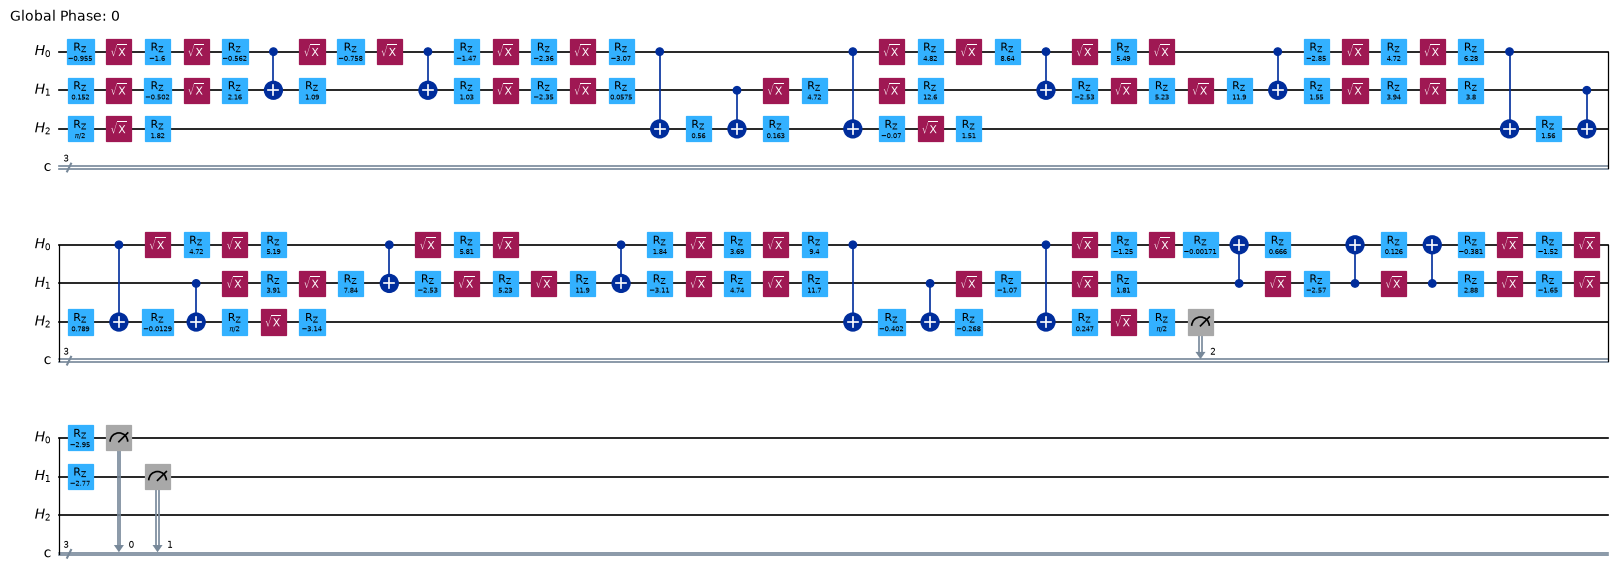


molecule C: C6 exact compilation, time point t = 299 x 2.5 ms, all-plus state, X-basis measurement: 3 CNOTs, depth 16, two-qubit depth 3


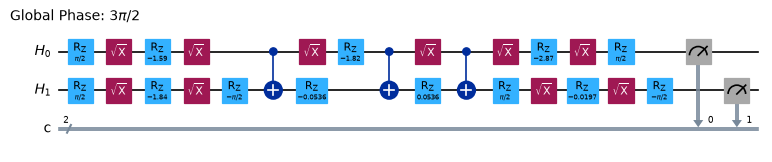


molecule A: C5, one product-formula step = 3 exact pair blocks (coupling + shared shift terms), 3 CNOTs each


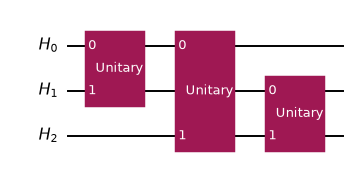

In [7]:
from qiskit import QuantumRegister, QuantumCircuit

def on_protons(qc):
    out = QuantumCircuit(QuantumRegister(qc.num_qubits, "H"), *qc.cregs, global_phase=qc.global_phase)
    return out.compose(qc)

for m in ("molecule A", "molecule C"):
    model = C.spin_model(m)
    best = C.transpile_for(C.full_circuit(C.evolution_circuit({"formula": "exact"}, model, 299), (0,) * model["n"], "X"), 3)
    met = C.circuit_metrics(best)
    print(f"\n{m}: C6 exact compilation, time point t = 299 x 2.5 ms, all-plus state, X-basis measurement: "
          f"{met['cx']} CNOTs, depth {met['depth']}, two-qubit depth {met['twoq_depth']}")
    display(on_protons(best).draw("mpl", fold=40, scale=0.6))
    plt.close("all")

model = C.spin_model("molecule A")
step = C.evolution_circuit({"formula": "pairfield"}, model, 1)
print("\nmolecule A: C5, one product-formula step = 3 exact pair blocks (coupling + shared shift terms), 3 CNOTs each")
display(on_protons(step).draw("mpl", scale=0.7))
plt.close("all")

## 6. Selection

In [8]:
summary = []
for m in MOLS:
    base = d[(d["molecule"] == m) & d["candidate"].str.startswith("C0")].iloc[0]
    acc = d[(d["molecule"] == m) & d["accepted"]]
    best = acc.sort_values(["deep_twoq_depth", "deep_depth", "E3_peak_pos_hz", "E4_peak_height_pct"]).iloc[0]  # ties: more accurate wins
    pf = acc[~acc["candidate"].str.startswith("C6")].sort_values(["deep_twoq_depth", "E3_peak_pos_hz", "deep_depth"]).iloc[0]
    for label, r in (("baseline", base), ("best overall", best), ("best product formula", pf)):
        summary.append({"molecule": m[-1], "role": label, "candidate": r["candidate"], "depth": r["deep_depth"],
                        "2q depth": r["deep_twoq_depth"], "CNOTs": r["deep_cx"], "circuits": r["circuits_on_hardware"],
                        "depth -%": round(100 * (1 - r["deep_depth"] / base["deep_depth"]), 1),
                        "2q -%": round(100 * (1 - r["deep_cx"] / base["deep_cx"]), 1),
                        "circuits -%": round(100 * (1 - r["circuits_on_hardware"] / base["circuits_on_hardware"]), 1),
                        "peak err (Hz)": round(r["E3_peak_pos_hz"], 3), "cosine vs exact": round(r["E2_cosine"], 4)})
display(pd.DataFrame(summary))

,molecule,role,candidate,depth,2q depth,CNOTs,circuits,depth -%,2q -%,circuits -%,peak err (Hz),cosine vs exact
0,A,baseline,C0 baseline (official),13460,5382,5382,4784,0.0,0.0,0.0,1.123,0.9328
1,A,best overall,C6 exact compilation per time point,80,19,19,2392,99.4,99.6,50.0,0.000,1.0000
2,A,best product formula,C5 shifts folded into pair blocks,8977,2691,2691,2392,33.3,50.0,50.0,0.373,0.9941
3,B,baseline,C0 baseline (official),13460,5382,5382,4784,0.0,0.0,0.0,0.917,0.9747
4,B,best overall,C6 exact compilation per time point,79,19,19,2392,99.4,99.6,50.0,0.000,1.0000
5,B,best product formula,C5 shifts folded into pair blocks,9274,2691,2691,2392,31.1,50.0,50.0,0.233,0.9982
6,C,baseline,C0 baseline (official),4490,1794,1794,2392,0.0,0.0,0.0,0.045,0.9999
7,C,best overall,C6 exact compilation per time point,16,3,3,598,99.6,99.8,75.0,0.000,1.0000
8,C,best product formula,C5 shifts folded into pair blocks,16,3,3,598,99.6,99.8,75.0,0.000,1.0000


**Best overall: C6, exact compilation of each time point.** It needs 19 CNOTs for A and B and 3 for
C, at every time point. That is 99.6 % fewer CNOTs than the deepest baseline circuit (5,382 and
1,794), with no Trotter error at all. The ΠZ symmetry halves the number of circuits for A and B
(4,784 → 2,392) and cuts it by 75 % for C (2,392 → 598).

**Best genuine product formula: C5 (shift terms folded into the pair blocks).** Its CNOT count and
two-qubit depth equal C2's (2,691, half the baseline), but it is about 3× more accurate than the
baseline: peak error 0.37 vs 1.12 Hz for A, cosine 0.994 vs 0.933. C2 has lower total depth (7,480 vs
8,977) but keeps the baseline's accuracy. For molecule C, C5 is already exact with 3 CNOTs.

**Limitations.**
- C6 builds each circuit from $e^{-iHt}$ computed classically. That is cheap for 2–3 spins, but the
  cost grows exponentially, so C6 is a compilation shortcut, not a scalable simulation algorithm.
- Product formulas cannot use fewer steps for A and B. Their spectra need at least 224 and 239 time
  points (aliasing), and steps larger than 2.5 ms lose accuracy.
- All numbers are ideal (noise-free). On a 3-qubit line, C6 needs 27 CNOTs (best layout and seed)
  instead of 19.